# Inferencia: predicción de precios para nuevas viviendas

Este notebook genera las predicciones de `SalePrice` para el conjunto de test con el modelo **champion** del Model Registry de MLflow, es decir, el ganador del torneo. La entrada son los **datos crudos** (`test.csv` tal como viene, sin ningún preprocesamiento manual) y la salida es un archivo con el precio estimado de cada vivienda.

Además:

- se construye y guarda un **pipeline de inferencia** que reúne todo el flujo en un solo objeto: selección de variables → preprocesamiento → modelo → conversión a dólares;
- se registra la ejecución como un **run de inferencia en MLflow**, con la versión del modelo usada, estadísticas de las predicciones, el archivo de predicciones y la gráfica de densidad.

## 1. Librerías

- **pandas** y **numpy**: manejo de datos.
- **yaml**: lectura de la lista de features desde `pipeline_config.yaml`.
- **joblib**: carga del modelo ganador y guardado del pipeline de inferencia.
- **scikit-learn**: `Pipeline` y `FunctionTransformer` para armar el flujo de inferencia.
- **operator.itemgetter**: selecciona las columnas que usa el modelo. A diferencia de una función `lambda`, se puede guardar con joblib.
- **mlflow**: carga del modelo champion desde el Model Registry y registro del run de inferencia.

In [1]:
# Librerías
import os
from operator import itemgetter
from pathlib import Path

import joblib
import mlflow
import numpy as np
import pandas as pd
import yaml
from mlflow import MlflowClient
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer

pd.set_option("display.max_columns", None)

## 2. Carga de datos crudos, configuración y modelo champion

Se leen:

- **`test.csv`** sin modificar. Incluye las 80 columnas originales, aunque el modelo solo usa 30.
- **`MODEL_FEATURES`** desde `pipeline_config.yaml`: las 30 variables con las que se entrenó el modelo.
- **El modelo `champion`** desde el Model Registry de MLflow (`models:/house_pricing_A@champion`). Es el ganador del torneo, ya entrenado. Incluye el preprocesamiento completo (imputación, codificación, outliers, Yeo-Johnson y escalado), el modelo y la conversión de la predicción a dólares.

El notebook no necesita saber qué algoritmo es el champion: siempre carga el alias `champion`. Si un torneo nuevo elige otro ganador, este notebook lo usará automáticamente. También se consultan la **versión** del modelo, sus alias y el **algoritmo** (tomado del run de entrenamiento del que proviene), que quedan registrados en el run de inferencia.

La configuración de MLflow se lee de la sección `MLFLOW` de `pipeline_config.yaml`, la misma que usa el notebook del torneo. Las rutas siguen el mismo criterio que los demás notebooks: la raíz del proyecto se detecta automáticamente y la carpeta de datos se puede cambiar con la variable de entorno `DATA_DIR`.

In [2]:
# Carga de test crudo, lista de features y modelo champion desde el Model Registry
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
DATA_DIR = Path(os.getenv("DATA_DIR", PROJECT_ROOT / "data" / "raw"))
CONFIG_FILE = PROJECT_ROOT / "pipeline_config.yaml"
MODELS_DIR = PROJECT_ROOT / "models"
TEST_FILE = "test.csv"

TARGET = "SalePrice"
ID_COL = "Id"
CHAMPION_ALIAS = "champion"

config = yaml.safe_load(CONFIG_FILE.read_text(encoding="utf-8"))
MODEL_FEATURES = config["MODEL_FEATURES"]
MLFLOW_CONFIG = config["MLFLOW"]
REGISTERED_MODEL_NAME = MLFLOW_CONFIG["REGISTERED_MODEL_NAME"]

mlflow.set_tracking_uri(f"sqlite:///{(PROJECT_ROOT / MLFLOW_CONFIG['DB_FILE']).as_posix()}")
mlflow.set_experiment(MLFLOW_CONFIG["EXPERIMENT_NAME"])

test_raw = pd.read_csv(DATA_DIR / TEST_FILE)

champion_uri = f"models:/{REGISTERED_MODEL_NAME}@{CHAMPION_ALIAS}"
client = MlflowClient()
champion_version = client.get_model_version_by_alias(REGISTERED_MODEL_NAME, CHAMPION_ALIAS)
champion_algorithm = client.get_run(champion_version.run_id).data.tags["algorithm"]
best_model = mlflow.sklearn.load_model(champion_uri)

print(f"Test crudo: {test_raw.shape} | Features del modelo: {len(MODEL_FEATURES)}")
print(f"Modelo: {champion_uri} -> versión {champion_version.version} ({champion_algorithm}) | alias: {champion_version.aliases}")
print(f"Pasos del modelo champion: {[name for name, _ in best_model.regressor_.steps]}")

Test crudo: (1459, 80) | Features del modelo: 30
Modelo: models:/house_pricing_A@champion -> versión 4 (GradientBoosting) | alias: ['champion', 'gradientboosting']
Pasos del modelo champion: ['preprocessing', 'model']


## 3. Pipeline de inferencia

Se arma un `Pipeline` con dos pasos:

1. **`selector`**: toma de los datos crudos solo las 30 columnas que usa el modelo, en el orden correcto. Así el pipeline acepta el archivo completo, aunque traiga columnas adicionales como `Id`.
2. **`model`**: el modelo champion. Aplica el preprocesamiento aprendido en entrenamiento, predice el logaritmo del precio y lo convierte a dólares.

No se vuelve a entrenar nada: el selector no aprende parámetros y el modelo ya está ajustado. El pipeline se guarda en `models/inference_pipeline.joblib`, de modo que cualquier aplicación o notebook futuro pueda cargarlo y predecir con `inference_pipeline.predict(datos_crudos)`.

In [3]:
# Construcción y guardado del pipeline de inferencia
INFERENCE_PIPELINE_FILE = MODELS_DIR / "inference_pipeline.joblib"

inference_pipeline = Pipeline(steps=[
    ("selector", FunctionTransformer(itemgetter(MODEL_FEATURES))),
    ("model", best_model),
])

joblib.dump(inference_pipeline, INFERENCE_PIPELINE_FILE)
print(f"Pipeline de inferencia guardado en: {INFERENCE_PIPELINE_FILE.relative_to(PROJECT_ROOT)}")
inference_pipeline

Pipeline de inferencia guardado en: models\inference_pipeline.joblib


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('selector', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",operator.item... 'HeatingQC'])
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",None
,"kw_args kw_args: dict, default=NoneDictionary of a

## 4. Predicción sobre el conjunto de test

Se vuelve a cargar el pipeline desde el archivo, tal como se haría en producción, y se le pasan los datos crudos de test. El resultado es el precio estimado en dólares de cada vivienda.

Antes de guardar se verifica que las predicciones sean válidas:

- Hay una predicción por cada vivienda de test.
- No hay valores vacíos.
- Todos los precios son positivos.

Por último, se comparan las estadísticas de los precios predichos con las de los precios reales de entrenamiento. Deben estar en rangos parecidos; una diferencia muy grande indicaría un problema en el flujo.

In [4]:
# Predicción con el pipeline cargado desde disco y verificaciones
TRAIN_FILE = "train.csv"

pipeline_loaded = joblib.load(INFERENCE_PIPELINE_FILE)
predictions = pipeline_loaded.predict(test_raw)

print(f"Predicciones: {len(predictions)} | Viviendas en test: {len(test_raw)}")
print(f"Valores vacíos: {np.isnan(predictions).sum()} | Precios <= 0: {(predictions <= 0).sum()}")

train_prices = pd.read_csv(DATA_DIR / TRAIN_FILE, usecols=[TARGET])[TARGET]
pd.DataFrame({
    "precio_real_train": train_prices.describe(),
    "precio_predicho_test": pd.Series(predictions).describe(),
}).style.format("{:,.0f}")

Predicciones: 1459 | Viviendas en test: 1459
Valores vacíos: 0 | Precios <= 0: 0


,precio_real_train,precio_predicho_test
count,"1,460","1,459"
mean,"180,921","177,187"
std,"79,443","76,087"
min,"34,900","40,534"
25%,"129,975","127,801"
50%,"163,000","156,264"
75%,"214,000","207,464"
max,"755,000","555,089"


## 5. Guardado de las predicciones

Las predicciones se guardan en `data/processed/predictions.csv` con dos columnas, `Id` y `SalePrice`. Es el mismo formato de `sample_submission.csv`, así que el archivo se puede usar directamente como envío.

Antes de guardar se comprueba que las columnas y el número de filas coincidan con ese archivo de referencia.

In [5]:
# Guardado de predicciones en formato de envío (Id, SalePrice)
PREDICTIONS_FILE = PROJECT_ROOT / "data" / "processed" / "predictions.csv"
SAMPLE_SUBMISSION_FILE = "sample_submission.csv"

submission = pd.DataFrame({ID_COL: test_raw[ID_COL], TARGET: predictions})

sample = pd.read_csv(DATA_DIR / SAMPLE_SUBMISSION_FILE)
assert list(submission.columns) == list(sample.columns), "Las columnas no coinciden con sample_submission.csv"
assert len(submission) == len(sample), "El número de filas no coincide con sample_submission.csv"

submission.to_csv(PREDICTIONS_FILE, index=False)
print(f"Predicciones guardadas en: {PREDICTIONS_FILE.relative_to(PROJECT_ROOT)}")
submission.head()

Predicciones guardadas en: data\processed\predictions.csv


,Id,SalePrice
0,1461,123015.074249
1,1462,152817.845498
2,1463,184505.753473
3,1464,189517.641313
4,1465,190463.492326


## 6. Distribución de los precios: reales en train vs. predichos en test

La gráfica compara en un mismo eje dos distribuciones de precios:

- **Azul**: los precios reales de las viviendas de entrenamiento (`train.csv`).
- **Naranja**: los precios que el pipeline del modelo ganador predijo para las viviendas de test.

Las líneas punteadas marcan la **mediana** de cada una, es decir, el precio que deja la mitad de las viviendas por debajo y la otra mitad por encima.

Sirve como revisión visual del modelo. Si las dos curvas tienen una forma y una posición parecidas, el modelo produce precios coherentes con el mercado que aprendió. Es normal que la curva predicha sea algo más angosta y llegue menos lejos en los precios altos: los modelos tienden a acercar sus estimaciones al centro y no reproducen del todo los casos extremos.

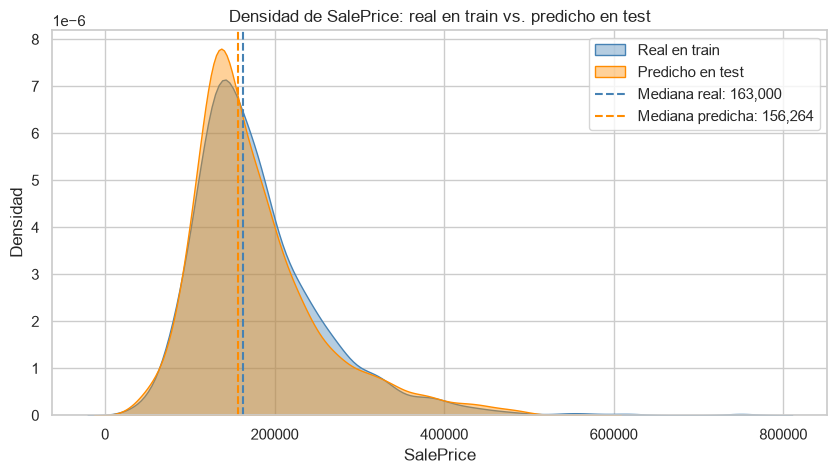

In [6]:
# Densidad de SalePrice real (train) vs. predicho por el pipeline (test)
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(10, 5))
sns.kdeplot(x=train_prices, fill=True, alpha=0.4, color="steelblue", label="Real en train", ax=ax)
sns.kdeplot(data=submission, x=TARGET, fill=True, alpha=0.4, color="darkorange", label="Predicho en test", ax=ax)
ax.axvline(train_prices.median(), color="steelblue", linestyle="--", label=f"Mediana real: {train_prices.median():,.0f}")
ax.axvline(submission[TARGET].median(), color="darkorange", linestyle="--", label=f"Mediana predicha: {submission[TARGET].median():,.0f}")
ax.set_title(f"Densidad de {TARGET}: real en train vs. predicho en test")
ax.set_xlabel(TARGET)
ax.set_ylabel("Densidad")
ax.legend()
plt.show()

## 7. Registro del run de inferencia en MLflow

La ejecución de este notebook se registra como un run llamado **`inferencia`** en el mismo experimento del torneo, para saber siempre qué modelo generó qué predicciones:

- **Etiquetas y parámetros**: el modelo registrado, la versión, el algoritmo y los alias del champion usado, el run de entrenamiento del que proviene y el archivo de entrada.
- **Métricas**: cantidad de predicciones, valores inválidos (vacíos o ≤ 0) y estadísticas de los precios predichos (media, mediana, desviación, mínimo y máximo).
- **Artefactos**: el archivo `predictions.csv` y la gráfica de densidad de la sección anterior.

In [7]:
# Run de inferencia en MLflow: modelo usado, estadísticas, predicciones y gráfica
with mlflow.start_run(run_name="inferencia") as run:
    mlflow.set_tags({
        "stage": "inferencia",
        "registered_model": REGISTERED_MODEL_NAME,
        "model_alias": CHAMPION_ALIAS,
        "model_version": champion_version.version,
        "algorithm": champion_algorithm,
        "model_aliases": ", ".join(champion_version.aliases),
        "training_run_id": champion_version.run_id,
    })
    mlflow.log_params({"model_uri": champion_uri, "input_file": TEST_FILE, "n_features": len(MODEL_FEATURES)})
    mlflow.log_metrics({
        "n_predictions": len(predictions),
        "n_invalid": int((~np.isfinite(predictions)).sum() + (predictions <= 0).sum()),
        "pred_mean": float(np.mean(predictions)),
        "pred_median": float(np.median(predictions)),
        "pred_std": float(np.std(predictions)),
        "pred_min": float(np.min(predictions)),
        "pred_max": float(np.max(predictions)),
    })
    mlflow.log_artifact(str(PREDICTIONS_FILE))
    mlflow.log_figure(fig, "densidad_real_train_vs_predicho_test.png")

print(f"Run de inferencia registrado: {run.info.run_name} ({run.info.run_id}) | modelo {REGISTERED_MODEL_NAME} v{champion_version.version} ({champion_algorithm})")

Run de inferencia registrado: inferencia (80822d2fa3ed41d39e3bf3335219c0ba) | modelo house_pricing_A v4 (GradientBoosting)
